# Genesis Mission Funding and Collaboration Dashboard

This dashboard summarizes BASELINE and UFR funding by Genesis Mission Challenge, program office contribution, and collaboration opportunity. Validation and confidence details are retained as traceability appendix material in the exported static HTML report.


In [1]:
from pathlib import Path
from html import escape
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display


def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing pyproject.toml")


PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from programming_ontology import paths
from programming_ontology.asksage_classifier import (
    default_credentials_path,
    resolve_asksage_openai_base_url,
)
from programming_ontology.classify_programming import run_classification_pipeline

paths.ensure_output_dirs()

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 220)
plt.style.use("default")


def format_money(value):
    value = 0 if pd.isna(value) else float(value)
    sign = "-" if value < 0 else ""
    value = abs(value)
    if value >= 1_000_000_000:
        return f"{sign}${value / 1_000_000_000:,.2f}B"
    if value >= 1_000_000:
        return f"{sign}${value / 1_000_000:,.1f}M"
    return f"{sign}${value:,.0f}"


def bool_env(name, default=False):
    raw = os.environ.get(name, "").strip().casefold()
    if not raw:
        return default
    return raw in {"1", "true", "yes", "y", "on"}


def optional_int_env(name):
    raw = os.environ.get(name, "").strip()
    return int(raw) if raw else None


In [2]:
REQUIRED_ARTIFACT_PATHS = {
    "row-level classifications": paths.PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH,
    "reviewed classifications": paths.REVIEWED_PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH,
    "office claim validation": paths.OFFICE_CLAIM_VALIDATION_PATH,
    "challenge coverage summary": paths.CHALLENGE_COVERAGE_SUMMARY_PATH,
    "office challenge evidence": paths.OFFICE_CHALLENGE_EVIDENCE_PATH,
    "WBS challenge summary": paths.WBS_CHALLENGE_SUMMARY_PATH,
    "classified ontology graph": paths.CLASSIFIED_ONTOLOGY_GRAPH_PATH,
}


def artifact_ready(path):
    return path.exists() and path.stat().st_size > 0


missing_artifacts = [
    name for name, path in REQUIRED_ARTIFACT_PATHS.items() if not artifact_ready(path)
]
REFRESH_ARTIFACTS_WITH_ASKSAGE = bool_env("REFRESH_ARTIFACTS_WITH_ASKSAGE", default=False)
AUTO_REFRESH_MISSING_ARTIFACTS = bool_env("AUTO_REFRESH_MISSING_ARTIFACTS", default=True)
ASKSAGE_TOP_K = int(os.environ.get("ASKSAGE_TOP_K", "5"))
ASKSAGE_LIMIT = optional_int_env("ASKSAGE_LIMIT")
ASKSAGE_REASONING_EFFORT = os.environ.get("ASKSAGE_REASONING_EFFORT", "medium").strip()
ASKSAGE_CREDENTIALS_PATH = default_credentials_path()
ASKSAGE_MODEL = os.environ.get("ASKSAGE_MODEL", "").strip() or None
ASKSAGE_OPENAI_BASE_URL = resolve_asksage_openai_base_url(credentials_path=ASKSAGE_CREDENTIALS_PATH)

should_refresh = REFRESH_ARTIFACTS_WITH_ASKSAGE or (
    AUTO_REFRESH_MISSING_ARTIFACTS and bool(missing_artifacts)
)

print(f"Using Ask Sage credentials file: {ASKSAGE_CREDENTIALS_PATH}")
print(f"Resolved OpenAI SDK base URL: {ASKSAGE_OPENAI_BASE_URL}")

if should_refresh:
    if missing_artifacts:
        display(Markdown("Refreshing because required artifacts are missing: " + ", ".join(missing_artifacts)))
    else:
        display(Markdown("Refreshing artifacts with Ask Sage because `REFRESH_ARTIFACTS_WITH_ASKSAGE` is enabled."))
    refresh_outputs = run_classification_pipeline(
        classifier="asksage",
        model=ASKSAGE_MODEL,
        top_k=ASKSAGE_TOP_K,
        reasoning_effort=ASKSAGE_REASONING_EFFORT,
        limit=ASKSAGE_LIMIT,
        resume_cache=True,
        audit_cache_path=paths.ASKSAGE_CLASSIFICATION_AUDIT_PATH,
        write_outputs=True,
    )
    display(Markdown(f"Refreshed **{len(refresh_outputs['classifications']):,}** rows with Ask Sage."))
else:
    if missing_artifacts:
        raise FileNotFoundError(
            "Required dashboard artifacts are missing and auto-refresh is disabled: "
            + ", ".join(missing_artifacts)
        )
    display(Markdown("Using existing processed artifacts. Set `REFRESH_ARTIFACTS_WITH_ASKSAGE=1` to regenerate them with Ask Sage."))


Using Ask Sage credentials file: C:\Users\Cameron.Webster\Python\ProgrammingOntology\credentials.json
Resolved OpenAI SDK base URL: https://api.nnsa.asksage.ai/server/openai/v1


Using existing processed artifacts. Set `REFRESH_ARTIFACTS_WITH_ASKSAGE=1` to regenerate them with Ask Sage.

In [3]:
classifications = pd.read_csv(paths.PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH)
reviewed_classifications = pd.read_csv(paths.REVIEWED_PROGRAMMING_CHALLENGE_CLASSIFICATIONS_PATH)
office_claim_validation = pd.read_csv(paths.OFFICE_CLAIM_VALIDATION_PATH)
challenge_coverage = pd.read_csv(paths.CHALLENGE_COVERAGE_SUMMARY_PATH)
office_challenge_evidence = pd.read_csv(paths.OFFICE_CHALLENGE_EVIDENCE_PATH)
wbs_challenge_summary = pd.read_csv(paths.WBS_CHALLENGE_SUMMARY_PATH)

for frame in [classifications, reviewed_classifications, office_claim_validation, challenge_coverage, office_challenge_evidence, wbs_challenge_summary]:
    if "five_year_total" in frame.columns:
        frame["five_year_total"] = pd.to_numeric(frame["five_year_total"], errors="coerce").fillna(0.0)

display(Markdown(f"""
## Loaded Artifacts

- Raw classifier rows (diagnostic): **{len(classifications):,}**
- Reviewed evidence rows: **{len(reviewed_classifications):,}**
- Office-challenge claims: **{len(office_claim_validation):,}**
- Positive BASELINE/UFR evidence: **{format_money(office_challenge_evidence['five_year_total'].sum())}**
"""))


## Loaded Artifacts

- Raw classifier rows (diagnostic): **61**
- Reviewed evidence rows: **61**
- Office-challenge claims: **32**
- Positive BASELINE/UFR evidence: **$4.98B**


,claim_count,five_year_total,five_year_total_display
validation_status,,,
validated,8,$1.99B,$1.99B
needs_review,8,$873.6M,$873.6M
unfunded,16,$0,$0


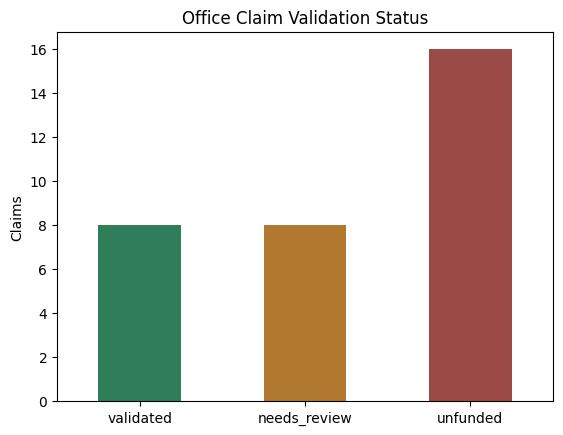

In [4]:
status_counts = office_claim_validation["validation_status"].value_counts().reindex(["validated", "needs_review", "unfunded"], fill_value=0)
status_funding = office_claim_validation.groupby("validation_status")["five_year_total"].sum().reindex(["validated", "needs_review", "unfunded"], fill_value=0.0)

executive_summary = pd.DataFrame(
    {
        "claim_count": status_counts,
        "five_year_total": status_funding.map(format_money),
        "five_year_total_display": status_funding.map(format_money),
    }
)
display(executive_summary)

ax = status_counts.plot(kind="bar", color=["#2f7d59", "#b1792f", "#9a4b45"], rot=0)
ax.set_title("Office Claim Validation Status")
ax.set_xlabel("")
ax.set_ylabel("Claims")
plt.show()

## Lead Office Accountability

These tables and visuals focus only on Genesis Mission Challenge claims where a program office is identified as the lead. The execution check compares each lead claim against actual BASELINE and UFR programming rows where that same office is funding work classified to the claimed challenge.


### Which offices claim lead responsibility?

,challenge_name,lead_program_office,execution_signal,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,high_confidence_count,medium_confidence_count,low_confidence_count,review_flag_count,evidence_wbs_names
5,Safeguarding Nuclear Materials from Proliferation Threats,NA20,"Executing, review evidence",needs_review,1,1,$342.0M,0,0,1,1,PD
8,Accelerating Business and Management Processes for National Security Missions,NA-MB,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
10,Accelerating Nuclear Enterprise Acquisition,NA-PAS,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
17,Integrating Design and Production Operations for Nuclear Deterrence,NA12,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
9,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",NA19,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
23,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NA90,No BASELINE/UFR evidence found,unfunded,0,0,$0,0,0,0,0,NaN
27,Harnessing America’s Historic Nuclear Data and Research,NA11,Executing with clear evidence,validated,1,1,$44.1M,0,1,0,0,Secondary Assessment Technologies
28,Increasing Experimental Capacity at Nuclear Research Facilities,NA11,Executing with clear evidence,validated,7,6,$915.8M,0,3,4,2,Artificial Intelligence for Nuclear Security (AI4NS); Computational Systems & Software Environment; Delivery Environments (formerly WSEAT); Facility Operations (formerly also Target Production); HED & Ignition Scienc...
24,(CUI) Preventing AI-Induced Nuclear Proliferation,NA80,Executing with clear evidence,validated,1,1,$40.0M,1,0,0,0,Nuclear Threat Science (NA-82)
26,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",NA80,Executing with clear evidence,validated,2,2,$92.5M,2,0,0,0,Nuclear Incident Preparedness and Collaboration (NA-81); Nuclear Incident Response (NA-84)


### Lead office by Genesis Mission Challenge

lead_program_office,NA-MB,NA-PAS,NA11,NA12,NA19,NA20,NA80,NA90
challenge_name,,,,,,,,
(CUI) Preventing AI-Induced Nuclear Proliferation,,,,,,,validated,
Accelerating Business and Management Processes for National Security Missions,unfunded,,,,,,,
"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",,,,,unfunded,,,
Accelerating Nuclear Enterprise Acquisition,,unfunded,,,,,,
"Accelerating Nuclear Threat Assessment, Preparedness, and Response",,,,,,,validated,
Harnessing America’s Historic Nuclear Data and Research,,,validated,,,,,
Increasing Experimental Capacity at Nuclear Research Facilities,,,validated,,,,,
Integrating Design and Production Operations for Nuclear Deterrence,,,,unfunded,,,,
Safeguarding Nuclear Materials from Proliferation Threats,,,,,,needs_review,,


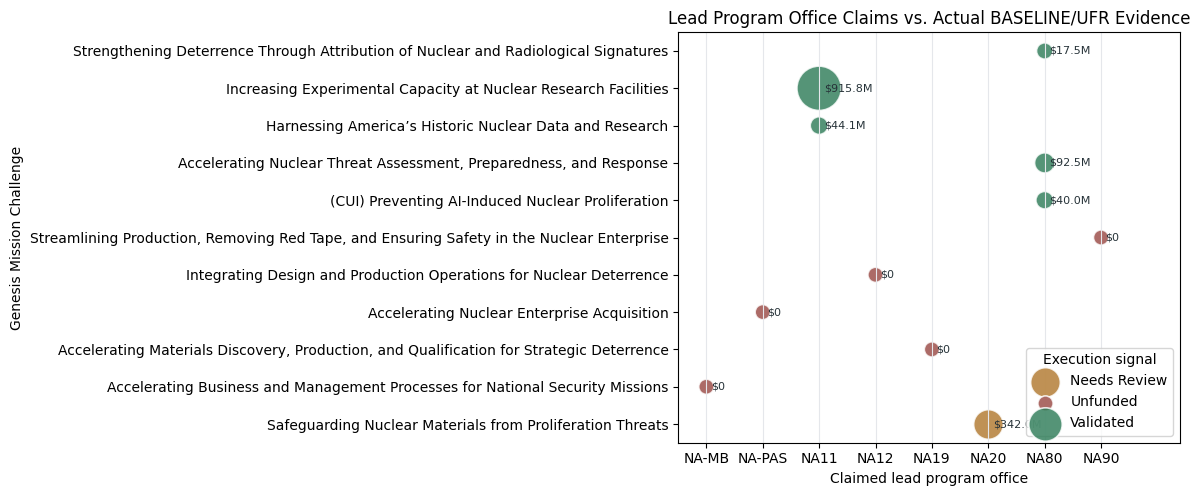

In [5]:
LEAD_STATUS_COLORS = {
    "validated": "#2f7d59",
    "needs_review": "#b1792f",
    "unfunded": "#9a4b45",
}
FUNDING_LEVEL_COLORS = {"BASELINE": "#4c78a8", "UFR": "#f58518"}
FY_COLUMNS = ["fy2028", "fy2029", "fy2030", "fy2031", "fy2032"]

lead_claims = office_claim_validation.loc[
    office_claim_validation["claim_role"].astype(str).str.casefold().eq("lead")
].copy()
lead_claims = lead_claims.rename(columns={"claimed_office": "lead_program_office"})
lead_claims["execution_signal"] = lead_claims["validation_status"].map(
    {
        "validated": "Executing with clear evidence",
        "needs_review": "Executing, review evidence",
        "unfunded": "No BASELINE/UFR evidence found",
    }
).fillna("Unknown")
lead_claims["five_year_total_display"] = lead_claims["five_year_total"].map(format_money)
lead_claims_display = lead_claims[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "evidence_row_count",
        "evidence_wbs_count",
        "five_year_total_display",
        "high_confidence_count",
        "medium_confidence_count",
        "low_confidence_count",
        "review_flag_count",
        "evidence_wbs_names",
    ]
].sort_values(["validation_status", "lead_program_office", "challenge_name"])

display(Markdown("### Which offices claim lead responsibility?"))
display(lead_claims_display)

lead_claim_matrix = lead_claims.pivot_table(
    index="challenge_name",
    columns="lead_program_office",
    values="validation_status",
    aggfunc=lambda values: "; ".join(sorted(set(values))),
    fill_value="",
)
display(Markdown("### Lead office by Genesis Mission Challenge"))
display(lead_claim_matrix)

if not lead_claims.empty:
    challenges_order = lead_claims["challenge_name"].drop_duplicates().tolist()
    offices_order = sorted(lead_claims["lead_program_office"].drop_duplicates())
    x_positions = {office: index for index, office in enumerate(offices_order)}
    y_positions = {challenge: index for index, challenge in enumerate(challenges_order)}
    max_amount = max(float(lead_claims["five_year_total"].max()), 1.0)

    fig, ax = plt.subplots(figsize=(12, max(4.5, 0.46 * len(challenges_order))))
    for status, status_rows in lead_claims.groupby("validation_status"):
        amounts = status_rows["five_year_total"].astype(float).clip(lower=0.0)
        sizes = 120 + (amounts / max_amount) * 900
        ax.scatter(
            status_rows["lead_program_office"].map(x_positions),
            status_rows["challenge_name"].map(y_positions),
            s=sizes,
            color=LEAD_STATUS_COLORS.get(status, "#6b7280"),
            alpha=0.82,
            edgecolor="white",
            linewidth=1.2,
            label=status.replace("_", " ").title(),
        )
    for _, row in lead_claims.iterrows():
        ax.text(
            x_positions[row["lead_program_office"]] + 0.08,
            y_positions[row["challenge_name"]],
            format_money(row["five_year_total"]),
            va="center",
            fontsize=8,
            color="#263238",
        )
    ax.set_xticks(range(len(offices_order)))
    ax.set_xticklabels(offices_order)
    ax.set_yticks(range(len(challenges_order)))
    ax.set_yticklabels(challenges_order)
    ax.set_xlim(-0.5, max(len(offices_order) - 0.5, 0.5) + 0.9)
    ax.set_title("Lead Program Office Claims vs. Actual BASELINE/UFR Evidence")
    ax.set_xlabel("Claimed lead program office")
    ax.set_ylabel("Genesis Mission Challenge")
    ax.grid(axis="x", color="#e5e7eb", linewidth=0.8)
    ax.legend(title="Execution signal", loc="lower right")
    plt.tight_layout()
    plt.show()


### Lead office BASELINE/UFR funding by claimed mission

,challenge_name,lead_program_office,execution_signal,validation_status,baseline_display,ufr_display,lead_programmed_total_display,baseline_project_rows,ufr_project_rows,evidence_wbs_count,review_flag_count
0,Safeguarding Nuclear Materials from Proliferation Threats,NA20,"Executing, review evidence",needs_review,$0,$342.0M,$342.0M,0.0,1.0,1,1
1,Accelerating Business and Management Processes for National Security Missions,NA-MB,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
3,Accelerating Nuclear Enterprise Acquisition,NA-PAS,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
4,Integrating Design and Production Operations for Nuclear Deterrence,NA12,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
2,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",NA19,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
5,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NA90,No BASELINE/UFR evidence found,unfunded,$0,$0,$0,0.0,0.0,0,0
8,Harnessing America’s Historic Nuclear Data and Research,NA11,Executing with clear evidence,validated,$44.1M,$0,$44.1M,1.0,0.0,1,0
9,Increasing Experimental Capacity at Nuclear Research Facilities,NA11,Executing with clear evidence,validated,$111.5M,$804.3M,$915.8M,4.0,3.0,6,2
6,(CUI) Preventing AI-Induced Nuclear Proliferation,NA80,Executing with clear evidence,validated,$0,$40.0M,$40.0M,0.0,1.0,1,0
7,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",NA80,Executing with clear evidence,validated,$0,$92.5M,$92.5M,0.0,2.0,2,0


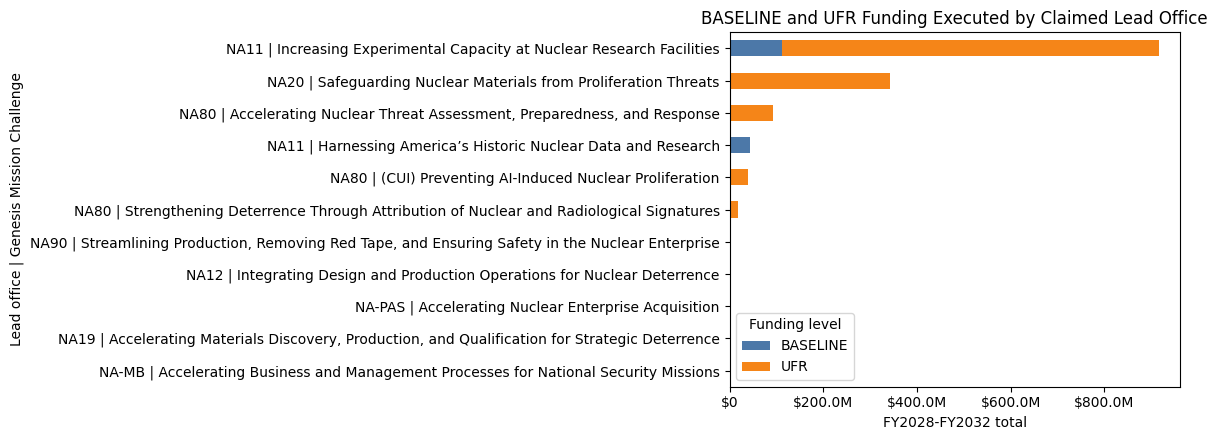

### Lead office project-level evidence

,lead_program_office,challenge_name,funding_level,five_year_total_display,fy2028_display,fy2029_display,fy2030_display,fy2031_display,fy2032_display,wbs_name,wbs_code,source_row_number,confidence,review_flag,scope_description
3,NA11,Harnessing America’s Historic Nuclear Data and Research,BASELINE,$44.1M,$7.2M,$8.1M,$9.2M,$9.8M,$9.8M,Secondary Assessment Technologies,OEB.001.003.001.004,15,medium,False,"AI/ML work across multiple HED experiments: analysis and modeling of data, with the goal of developing more refined approaches"
6,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$76.1M,$12.5M,$15.6M,$16.6M,$15.8M,$15.7M,HED & Ignition Science for Stockpile Applications (formerly Ignition),OEB.001.003.003.001,26,low,False,"AI for Ignition Applications, Double Shells, Experiment Analyses and Understanding, Simulations and Analysis Methods, Pulse Shaping Machine Learning (PUSH ML), Development and Interface with CMF"
7,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$2.0M,$1.0M,$1.0M,$0,$0,$0,"ICF Diagnostics & Instrumentation (formerly Diagnostics, Cryogenics & Experimental Support)",OEB.001.003.003.003,28,low,True,Constraining Mix using radiochemistry on NIF
5,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$19.5M,$5.0M,$4.7M,$4.8M,$2.5M,$2.5M,Facility Operations (formerly also Target Production),OEB.001.003.003.005,24,low,False,"Capability Development, ICF Operations, Develop experimental capabilities and support for target metrology in Fusion Yield Platforms"
4,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,BASELINE,$13.9M,$2.7M,$2.7M,$2.7M,$2.9M,$2.9M,Delivery Environments (formerly WSEAT),OEB.001.003.041.002,23,low,True,Investigation of novel physics modeling pertinent to reentry systems and the associated validation and uncertainty quantification (VUQ)
0,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,UFR,$346.6M,$64.0M,$66.6M,$69.2M,$72.0M,$74.9M,Artificial Intelligence for Nuclear Security (AI4NS),OEB.001.003.040.017,3,medium,False,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
2,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,UFR,$338.5M,$62.5M,$65.0M,$67.6M,$70.3M,$73.1M,Computational Systems & Software Environment,OEB.001.003.040.014,5,medium,False,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
1,NA11,Increasing Experimental Capacity at Nuclear Research Facilities,UFR,$119.2M,$22.0M,$22.9M,$23.8M,$24.7M,$25.7M,Artificial Intelligence for Nuclear Security (AI4NS),OEB.001.003.040.017,4,medium,False,"This effort aims to productionize several prototype AI tools to accelerate weapons design, modeling, and simulation workflows, such as the CHANDLER federated model, the Horizon Shield simulation workflow, and the CAD..."
8,NA20,Safeguarding Nuclear Materials from Proliferation Threats,UFR,$342.0M,$46.0M,$74.0M,$74.0M,$74.0M,$74.0M,PD,OEB.002.022.001,37,low,True,"This UFR will accelerate the application of AI to challenging proliferation detection scenarios, including through deployment and maturation of DNN R&D's Alexandria Data Management System; the development, prototypin..."
10,NA80,(CUI) Preventing AI-Induced Nuclear Proliferation,UFR,$40.0M,$8.0M,$8.0M,$8.0M,$8.0M,$8.0M,Nuclear Threat Science (NA-82),OEB.002.080.002,45,high,False,"Surge support for advancing AI-tools for rapid and effective response to nuclear and radiological events that require detailed analysis of vast and varied data, deploy AI tools to identify and mitigate sensitive info..."


In [6]:
positive_funding_rows = reviewed_classifications.loc[
    reviewed_classifications["funding_level"].astype(str).str.upper().isin(["BASELINE", "UFR"])
].copy()

lead_project_rows = positive_funding_rows.merge(
    lead_claims[["challenge_name", "lead_program_office", "validation_status", "execution_signal"]],
    left_on=["predicted_challenge", "normalized_funding_office"],
    right_on=["challenge_name", "lead_program_office"],
    how="inner",
)

for column in [*FY_COLUMNS, "five_year_total"]:
    if column in lead_project_rows.columns:
        lead_project_rows[column] = pd.to_numeric(lead_project_rows[column], errors="coerce").fillna(0.0)
        lead_project_rows[f"{column}_display"] = lead_project_rows[column].map(format_money)

if lead_project_rows.empty:
    lead_project_table = pd.DataFrame(
        columns=[
            "lead_program_office",
            "challenge_name",
            "funding_level",
            "five_year_total_display",
            "wbs_name",
            "wbs_code",
            "source_row_number",
            "confidence",
            "review_flag",
            "scope_description",
        ]
    )
    lead_project_funding = pd.DataFrame(
        columns=["lead_program_office", "challenge_name", "funding_level", "five_year_total"]
    )
else:
    lead_project_table = lead_project_rows[
        [
            "lead_program_office",
            "challenge_name",
            "funding_level",
            "five_year_total_display",
            "fy2028_display",
            "fy2029_display",
            "fy2030_display",
            "fy2031_display",
            "fy2032_display",
            "wbs_name",
            "wbs_code",
            "source_row_number",
            "confidence",
            "review_flag",
            "scope_description",
        ]
    ].sort_values(
        ["lead_program_office", "challenge_name", "funding_level", "five_year_total_display"],
        ascending=[True, True, True, False],
    )
    lead_project_funding = lead_project_rows.groupby(
        ["lead_program_office", "challenge_name", "funding_level"],
        as_index=False,
    ).agg(
        project_rows=("programming_record_id", "nunique"),
        wbs_count=("wbs_name", "nunique"),
        five_year_total=("five_year_total", "sum"),
    )

funding_amount_pivot = lead_project_funding.pivot_table(
    index=["lead_program_office", "challenge_name"],
    columns="funding_level",
    values="five_year_total",
    aggfunc="sum",
    fill_value=0.0,
).reset_index()
for funding_level in ["BASELINE", "UFR"]:
    if funding_level not in funding_amount_pivot.columns:
        funding_amount_pivot[funding_level] = 0.0

funding_count_pivot = lead_project_funding.pivot_table(
    index=["lead_program_office", "challenge_name"],
    columns="funding_level",
    values="project_rows",
    aggfunc="sum",
    fill_value=0,
).reset_index()
funding_count_pivot = funding_count_pivot.rename(
    columns={"BASELINE": "baseline_project_rows", "UFR": "ufr_project_rows"}
)
for column in ["baseline_project_rows", "ufr_project_rows"]:
    if column not in funding_count_pivot.columns:
        funding_count_pivot[column] = 0

lead_execution_summary = lead_claims[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "evidence_row_count",
        "evidence_wbs_count",
        "review_flag_count",
    ]
].merge(
    funding_amount_pivot,
    on=["lead_program_office", "challenge_name"],
    how="left",
).merge(
    funding_count_pivot,
    on=["lead_program_office", "challenge_name"],
    how="left",
)
for column in ["BASELINE", "UFR", "baseline_project_rows", "ufr_project_rows"]:
    lead_execution_summary[column] = pd.to_numeric(
        lead_execution_summary[column], errors="coerce"
    ).fillna(0)
lead_execution_summary["lead_programmed_total"] = (
    lead_execution_summary["BASELINE"] + lead_execution_summary["UFR"]
)
lead_execution_summary["baseline_display"] = lead_execution_summary["BASELINE"].map(format_money)
lead_execution_summary["ufr_display"] = lead_execution_summary["UFR"].map(format_money)
lead_execution_summary["lead_programmed_total_display"] = lead_execution_summary[
    "lead_programmed_total"
].map(format_money)
lead_execution_summary_display = lead_execution_summary[
    [
        "challenge_name",
        "lead_program_office",
        "execution_signal",
        "validation_status",
        "baseline_display",
        "ufr_display",
        "lead_programmed_total_display",
        "baseline_project_rows",
        "ufr_project_rows",
        "evidence_wbs_count",
        "review_flag_count",
    ]
].sort_values(["validation_status", "lead_program_office", "challenge_name"])

display(Markdown("### Lead office BASELINE/UFR funding by claimed mission"))
display(lead_execution_summary_display)

bar_source = lead_execution_summary.copy()
bar_source["lead_mission"] = (
    bar_source["lead_program_office"] + " | " + bar_source["challenge_name"]
)
bar_plot = bar_source.set_index("lead_mission")[["BASELINE", "UFR"]]
bar_plot = bar_plot.loc[bar_plot.sum(axis=1).sort_values().index]
if bar_plot.sum(axis=1).gt(0).any():
    ax = bar_plot.plot(
        kind="barh",
        stacked=True,
        figsize=(12, max(4.5, 0.4 * len(bar_plot))),
        color=[FUNDING_LEVEL_COLORS["BASELINE"], FUNDING_LEVEL_COLORS["UFR"]],
    )
    ax.set_title("BASELINE and UFR Funding Executed by Claimed Lead Office")
    ax.set_xlabel("FY2028-FY2032 total")
    ax.set_ylabel("Lead office | Genesis Mission Challenge")
    ax.xaxis.set_major_formatter(lambda value, _: format_money(value))
    ax.legend(title="Funding level")
    plt.tight_layout()
    plt.show()
else:
    display(Markdown("No BASELINE or UFR funding rows were found for lead office claims."))

display(Markdown("### Lead office project-level evidence"))
display(lead_project_table)


In [7]:
claim_matrix = office_claim_validation.pivot_table(
    index="claimed_office",
    columns="challenge_name",
    values="validation_status",
    aggfunc=lambda values: "; ".join(sorted(set(values))),
    fill_value="",
)
display(claim_matrix)

challenge_name,(CUI) Preventing AI-Induced Nuclear Proliferation,Accelerating Business and Management Processes for National Security Missions,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",Accelerating Nuclear Enterprise Acquisition,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",Harnessing America’s Historic Nuclear Data and Research,Increasing Experimental Capacity at Nuclear Research Facilities,Integrating Design and Production Operations for Nuclear Deterrence,Safeguarding Nuclear Materials from Proliferation Threats,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",Strengthening Deterrence Through Attribution of Nuclear and Radiological Signatures
claimed_office,,,,,,,,,,,
NA-MB,,unfunded,,,,,,,,,
NA-PAS,,,,unfunded,,,,,,,
NA11,,,validated,,,validated,validated,needs_review,,validated,
NA12,,,,,,unfunded,,unfunded,,unfunded,
NA19,,,unfunded,,,,,unfunded,,unfunded,
NA20,needs_review,,,,unfunded,unfunded,needs_review,,needs_review,,validated
NA70,,,,,,,,,,needs_review,
NA80,validated,,,,validated,unfunded,unfunded,,unfunded,,validated
NA90,,,,,,,,,,unfunded,


In [8]:
challenge_display = challenge_coverage.copy()
challenge_display["five_year_total_display"] = challenge_display["five_year_total"].map(format_money)
display(
    challenge_display[
        [
            "challenge_name",
            "claim_count",
            "validated",
            "needs_review",
            "unfunded",
            "evidence_row_count",
            "evidence_wbs_count",
            "five_year_total_display",
            "claimed_offices",
            "actual_funding_offices",
        ]
    ]
)

,challenge_name,claim_count,validated,needs_review,unfunded,evidence_row_count,evidence_wbs_count,five_year_total_display,claimed_offices,actual_funding_offices
0,(CUI) Preventing AI-Induced Nuclear Proliferation,2,1,1,0,2,2,$205.0M,NA20; NA80,NA20; NA80
1,Accelerating Business and Management Processes for National Security Missions,2,0,1,1,5,5,$79.7M,NA-MB; NAIM,NA11; NAIM
2,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",2,1,0,1,10,8,$323.6M,NA11; NA19,NA11; NA90
3,Accelerating Nuclear Enterprise Acquisition,2,0,1,1,3,3,$26.7M,NA-PAS; NAIM,NA20; NA30; NAIM
4,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",2,1,0,1,2,2,$92.5M,NA20; NA80,NA80
5,Harnessing America’s Historic Nuclear Data and Research,5,1,0,4,1,1,$44.1M,NA11; NA12; NA20; NA80; NAIM,NA11
6,Increasing Experimental Capacity at Nuclear Research Facilities,3,1,1,1,17,15,$1.83B,NA11; NA20; NA80,NA11; NA12; NA20; NA90; NAESH; NAIM
7,Integrating Design and Production Operations for Nuclear Deterrence,3,0,1,2,4,4,$249.5M,NA11; NA12; NA19,NA11; NA30
8,Safeguarding Nuclear Materials from Proliferation Threats,3,0,1,2,1,1,$342.0M,NA20; NA80; NAIM,NA20
9,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",6,1,2,3,7,6,$1.62B,NA11; NA12; NA19; NA70; NA90; NAESH,NA11; NA20; NA70; NAESH; NAIM


In [9]:
unclaimed_evidence = office_challenge_evidence.loc[~office_challenge_evidence["is_claimed"].astype(bool)].copy()
unclaimed_evidence["five_year_total_display"] = unclaimed_evidence["five_year_total"].map(format_money)
unclaimed_evidence = unclaimed_evidence.sort_values("five_year_total", ascending=False)
display(
    unclaimed_evidence[
        [
            "challenge_name",
            "normalized_funding_office",
            "evidence_row_count",
            "evidence_wbs_count",
            "five_year_total_display",
            "evidence_wbs_names",
        ]
    ]
)


,challenge_name,normalized_funding_office,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
24,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NAIM,2,2,$1.10B,Artificial Intelligence - Program Work; Enterprise Operations
13,Increasing Experimental Capacity at Nuclear Research Facilities,NA12,2,1,$483.4M,Multi-Weapon Systems (formerly MTP)
14,Increasing Experimental Capacity at Nuclear Research Facilities,NA90,5,5,$363.2M,"32-D-XXX New Central Computing Facility, Y-12; LANL - 23-D-517 Electrical Power Capacity Upgrade; Maintenance at Working Facilities; Operations of Facilties; Other Project Costs"
3,Accelerating Business and Management Processes for National Security Missions,NA11,4,4,$64.5M,Dynamic Materials Properties; HED & Ignition Science for Stockpile Applications (formerly Ignition); Hydrodynamic & Subcritical Execution Support (formerly RDC&S); ICF Diagnostics & Instrumentation (formerly Diagnost...
16,Increasing Experimental Capacity at Nuclear Research Facilities,NAIM,1,1,$45.0M,Artificial Intelligence - Program Work
23,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",NA20,1,1,$17.5M,Civil Nuclear Cooperation & Engagement
8,Accelerating Nuclear Enterprise Acquisition,NA30,1,1,$16.2M,Reactor Systems & Component Technology
7,Accelerating Nuclear Enterprise Acquisition,NA20,1,1,$8.0M,Export Control
18,Integrating Design and Production Operations for Nuclear Deterrence,NA30,1,1,$5.5M,"Laboratory Facility Regulation, Compliance, & Protection"
5,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",NA90,1,1,$3.4M,Other Project Costs


In [10]:
office_summary = office_claim_validation.copy()
office_summary["five_year_total_display"] = office_summary["five_year_total"].map(format_money)
for office, office_rows in office_summary.groupby("claimed_office"):
    display(Markdown(f"## {office}"))
    display(
        office_rows[
            [
                "challenge_name",
                "claim_role",
                "validation_status",
                "evidence_row_count",
                "evidence_wbs_count",
                "five_year_total_display",
                "evidence_wbs_names",
            ]
        ].sort_values(["validation_status", "challenge_name"])
    )

## NA-MB

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
8,Accelerating Business and Management Processes for National Security Missions,lead,unfunded,0,0,$0,NaN


## NA-PAS

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
10,Accelerating Nuclear Enterprise Acquisition,lead,unfunded,0,0,$0,NaN


## NA11

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
4,Integrating Design and Production Operations for Nuclear Deterrence,partner,needs_review,3,3,$244.0M,Archiving & Support; Facility Operations (formerly also Target Production); Secondary Assessment Technologies
25,"Accelerating Materials Discovery, Production, and Qualification for Strategic Deterrence",partner,validated,9,7,$320.2M,Advanced Certification & Qualification (formerly Advanced Certification); Advanced Manufacturing Development; Aging & Lifetimes (formerly Enhanced Surveillance); Archiving & Support; Delivery Environments (formerly W...
27,Harnessing America’s Historic Nuclear Data and Research,lead,validated,1,1,$44.1M,Secondary Assessment Technologies
28,Increasing Experimental Capacity at Nuclear Research Facilities,lead,validated,7,6,$915.8M,Artificial Intelligence for Nuclear Security (AI4NS); Computational Systems & Software Environment; Delivery Environments (formerly WSEAT); Facility Operations (formerly also Target Production); HED & Ignition Scienc...
29,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",partner,validated,2,1,$408.8M,Artificial Intelligence for Nuclear Security (AI4NS)


... (12 outputs left out)

## NAESH

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
7,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",partner,needs_review,1,1,$75.0M,"Safety Analytics, Forecasting, Evaluation and Reporting (SAFER)"


## NAIM

,challenge_name,claim_role,validation_status,evidence_row_count,evidence_wbs_count,five_year_total_display,evidence_wbs_names
1,Accelerating Business and Management Processes for National Security Missions,partner,needs_review,1,1,$15.1M,Artificial Intelligence - Program Work
2,Accelerating Nuclear Enterprise Acquisition,partner,needs_review,1,1,$2.5M,Mission Contract Tasks
15,Harnessing America’s Historic Nuclear Data and Research,partner,unfunded,0,0,$0,NaN
20,Safeguarding Nuclear Materials from Proliferation Threats,partner,unfunded,0,0,$0,NaN


In [11]:
reviewed_display = reviewed_classifications.copy()
reviewed_display["five_year_total_display"] = reviewed_display["five_year_total"].map(format_money)
display(
    reviewed_display[
        [
            "programming_record_id",
            "source_row_number",
            "wbs_name",
            "source_sub_office",
            "normalized_funding_office",
            "funding_level",
            "original_predicted_challenge",
            "predicted_challenge",
            "confidence",
            "review_flag",
            "sme_review_decision",
            "sme_override_applied",
            "sme_notes",
            "sme_reviewer",
            "sme_review_date",
            "five_year_total_display",
            "scope_description",
        ]
    ].sort_values(["predicted_challenge", "normalized_funding_office", "wbs_name"])
)

,programming_record_id,source_row_number,wbs_name,source_sub_office,normalized_funding_office,funding_level,original_predicted_challenge,predicted_challenge,confidence,review_flag,sme_review_decision,sme_override_applied,sme_notes,sme_reviewer,sme_review_date,five_year_total_display,scope_description
35,programming_record:programming_data_csv:36,36,PD,NA22,NA20,BASELINE,(CUI) Preventing AI-Induced Nuclear Proliferation,(CUI) Preventing AI-Induced Nuclear Proliferation,high,True,needs_discussion,False,NaN,NaN,NaN,$165.0M,AI PROGRAM WORK
44,programming_record:programming_data_csv:45,45,Nuclear Threat Science (NA-82),NA82,NA80,UFR,"Accelerating Nuclear Threat Assessment, Preparedness, and Response",(CUI) Preventing AI-Induced Nuclear Proliferation,high,False,change,True,Corrected,Cam Webster,5/28/2026,$40.0M,"Surge support for advancing AI-tools for rapid and effective response to nuclear and radiological events that require detailed analysis of vast and varied data, deploy AI tools to identify and mitigate sensitive info..."
11,programming_record:programming_data_csv:12,12,Dynamic Materials Properties,NA11,NA11,UFR,Accelerating Business and Management Processes for National Security Missions,Accelerating Business and Management Processes for National Security Missions,low,False,accept,False,NaN,NaN,NaN,$9.1M,"The President, Secretary, and Administrator have declared expanded use of AI is a national, departmental, and agency priority. The NA-1 NNSA Planning and Programming Guidance for Fiscal years 2028-2032 Future Years N..."
26,programming_record:programming_data_csv:27,27,HED & Ignition Science for Stockpile Applications (formerly Ignition),NA11,NA11,UFR,Accelerating Business and Management Processes for National Security Missions,Accelerating Business and Management Processes for National Security Missions,low,True,needs_discussion,False,NaN,NaN,NaN,$20.4M,"The President, Secretary, and Administrator have declared expanded use of AI is a national, departmental, and agency priority. The NA-1 NNSA Planning and Programming Guidance for Fiscal years 2028-2032 Future Years N..."
12,programming_record:programming_data_csv:13,13,Hydrodynamic & Subcritical Execution Support (formerly RDC&S),NA11,NA11,UFR,Accelerating Business and Management Processes for National Security Missions,Accelerating Business and Management Processes for National Security Missions,low,True,needs_discussion,False,NaN,NaN,NaN,$30.0M,"The President, Secretary, and Administrator have declared expanded use of AI is a national, departmental, and agency priority. The NA-1 NNSA Planning and Programming Guidance for Fiscal years 2028-2032 Future Years N..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55,programming_record:programming_data_csv:56,56,"Safety Analytics, Forecasting, Evaluation and Reporting (SAFER)",NAESH,NAESH,DECREMENT,Harnessing America’s Historic Nuclear Data and Research,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",low,False,change,True,Corrected,Cam Webster,5/28/2026,-$22.5M,"Maintain NNSA Decision and Analytics Platform, develop new data analysis, operational, and/or artificial intelligence tools"
60,programming_record:programming_data_csv:61,61,Artificial Intelligence - Program Work,NAIM,NAIM,UFR,Accelerating Nuclear Enterprise Acquisition,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",low,False,change,True,Corrected,Cam Webster,5/28/2026,$636.6M,"This UFR requests funding vital for enabling AI Innovation and Collaboration, upgrading Core Computing infrastructure to enhance enterprise connectivity, developing and deploying secure AI Models and Tools, strengthe..."
56,programming_record:programming_data_csv:57,57,Enterprise Operations,NAIM,NAIM,BASELINE,Accelerating Nuclear Enterprise Acquisition,"Streamlining Production, Removing Red Tape, and Ensuring Safety in the Nuclear Enterprise",medium,False,change,True,Corrected,Cam We

In [12]:
from programming_ontology._dashboard_report import write_classification_dashboard_html

html = write_classification_dashboard_html(
    paths,
    reviewed_classifications=reviewed_classifications,
    office_claim_validation=office_claim_validation,
    challenge_coverage=challenge_coverage,
    office_challenge_evidence=office_challenge_evidence,
)
display(Markdown(f"Exported executive dashboard HTML to `{paths.CLASSIFICATION_DASHBOARD_HTML_PATH}`."))


Exported executive dashboard HTML to `C:\Users\Cameron.Webster\Python\ProgrammingOntology\outputs\reports\classification_dashboard.html`.